In [ ]:
#  Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Show every column when we print a table
pd.set_option("display.max_columns", None)

In [ ]:
##  Load the dataset from a CSV file

TARGET   = "relative_humidity_3pm"     # the column we want to predict
# -----------------------------------------------------------------

df = pd.read_csv(r"C:\Akshay\Data Analytics\TPM Assignments\Machine Learning\Projects\data_weather.csv")
df.head()

In [3]:
#  Inspect the data
print("Rows and columns:", df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

Rows and columns: (1095, 11)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   number                  1095 non-null   int64  
 1   air_pressure_9am        1092 non-null   float64
 2   air_temp_9am            1090 non-null   float64
 3   avg_wind_direction_9am  1091 non-null   float64
 4   avg_wind_speed_9am      1092 non-null   float64
 5   max_wind_direction_9am  1092 non-null   float64
 6   max_wind_speed_9am      1091 non-null   float64
 7   rain_accumulation_9am   1089 non-null   float64
 8   rain_duration_9am       1092 non-null   float64
 9   relative_humidity_9am   1095 non-null   float64
 10  relative_humidity_3pm   1095 non-null   float64
dtypes: float64(10), int64(1)
memory usage: 94.2 KB

Missing values per column:
number                    0
air_pressure_9am          3
air_temp_9am              5
a

In [4]:
df.describe().round(2)

,number,air_pressure_9am,air_temp_9am,avg_wind_direction_9am,avg_wind_speed_9am,max_wind_direction_9am,max_wind_speed_9am,rain_accumulation_9am,rain_duration_9am,relative_humidity_9am,relative_humidity_3pm
count,1095.00,1092.00,1090.00,1091.00,1092.00,1092.00,1091.00,1089.00,1092.00,1095.00,1095.00
mean,547.00,918.88,64.93,142.24,5.51,148.95,7.02,0.20,294.11,34.24,35.34
std,316.24,3.18,11.18,69.14,4.55,67.24,5.60,1.59,1598.08,25.47,22.52
min,0.00,907.99,36.75,15.50,0.69,28.90,1.19,0.00,0.00,6.09,5.30
25%,273.50,916.55,57.28,65.97,2.25,76.55,3.07,0.00,0.00,15.09,17.40
50%,547.00,918.92,65.72,166.00,3.87,177.30,4.94,0.00,0.00,23.18,24.38
75%,820.50,921.16,73.45,191.00,7.34,201.23,8.95,0.00,0.00,45.40,52.06
max,1094.00,929.32,98.91,343.40,23.55,312.20,29.84,24.02,17704.00,92.62,92.25


In [ ]:
#  cleaning
rows_before = len(df)

df = df.drop(columns=["number"])
df = df.dropna()

print("Rows before cleaning:", rows_before)
print("Rows after cleaning: ", len(df))
print("Rows removed:        ", rows_before - len(df))
print("Missing values left: ", df.isnull().sum().sum())

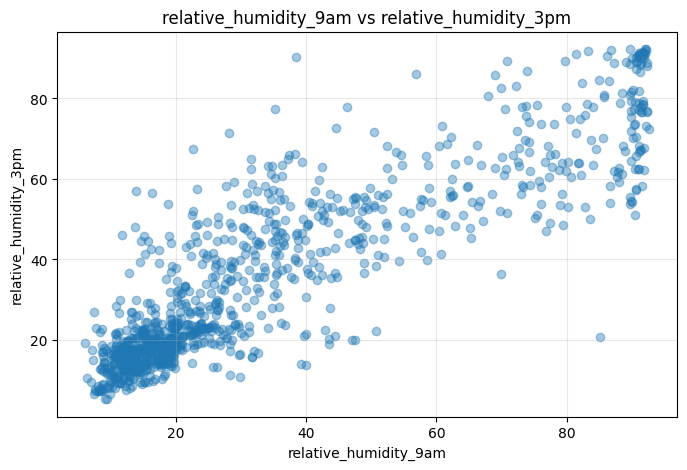

In [6]:
#  Visualize the relationships
FEATURE_TO_PLOT = "relative_humidity_9am"

plt.figure(figsize=(8, 5))
plt.scatter(df[FEATURE_TO_PLOT], df[TARGET], alpha=0.4)
plt.title(f"{FEATURE_TO_PLOT} vs {TARGET}")
plt.xlabel(FEATURE_TO_PLOT)
plt.ylabel(TARGET)
plt.grid(True, alpha=0.3)
plt.show()

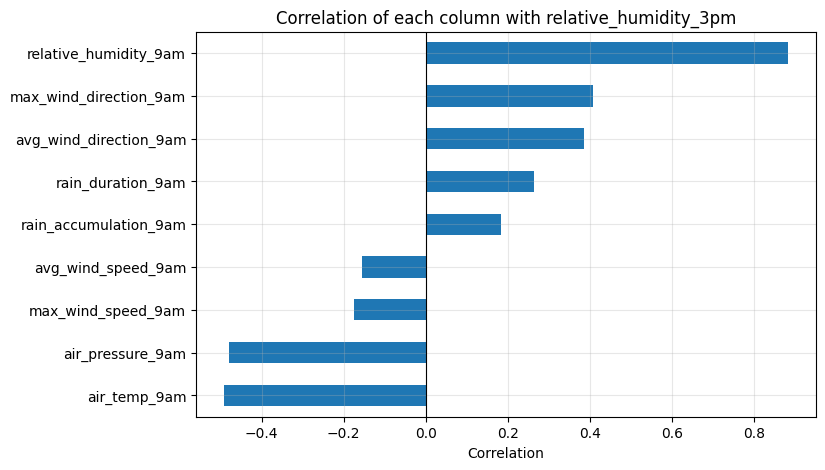

air_temp_9am             -0.491
air_pressure_9am         -0.480
max_wind_speed_9am       -0.174
avg_wind_speed_9am       -0.154
rain_accumulation_9am     0.182
rain_duration_9am         0.263
avg_wind_direction_9am    0.385
max_wind_direction_9am    0.406
relative_humidity_9am     0.881
Name: relative_humidity_3pm, dtype: float64

In [7]:
correlations = df.corr()[TARGET].drop(TARGET).sort_values()

plt.figure(figsize=(8, 5))
correlations.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.title(f"Correlation of each column with {TARGET}")
plt.xlabel("Correlation")
plt.grid(True, alpha=0.3)
plt.show()

correlations.round(3)

In [8]:
#  Separate the inputs (X) and the target (y)
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Features (X):", list(X.columns))
display(X.head())

print("Target (y):", TARGET)
display(y.head())

Features (X): ['air_pressure_9am', 'air_temp_9am', 'avg_wind_direction_9am', 'avg_wind_speed_9am', 'max_wind_direction_9am', 'max_wind_speed_9am', 'rain_accumulation_9am', 'rain_duration_9am', 'relative_humidity_9am']


,air_pressure_9am,air_temp_9am,avg_wind_direction_9am,avg_wind_speed_9am,max_wind_direction_9am,max_wind_speed_9am,rain_accumulation_9am,rain_duration_9am,relative_humidity_9am
0,918.060000,74.822000,271.100000,2.080354,295.400000,2.863283,0.0,0.0,42.420000
1,917.347688,71.403843,101.935179,2.443009,140.471549,3.533324,0.0,0.0,24.328697
2,923.040000,60.638000,51.000000,17.067852,63.700000,22.100967,0.0,20.0,8.900000
3,920.502751,70.138895,198.832133,4.337363,211.203341,5.190045,0.0,0.0,12.189102
4,921.160000,44.294000,277.800000,1.856660,136.500000,2.863283,8.9,14730.0,92.410000


Target (y): relative_humidity_3pm


0    36.160000
1    19.426597
2    14.460000
3    12.742547
4    76.740000
Name: relative_humidity_3pm, dtype: float64

In [9]:
#  Split the data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training examples:", len(X_train))
print("Testing examples: ", len(X_test))

Training examples: 851
Testing examples:  213


In [10]:
#  — Create and train the first model (Linear Regression)
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

print("Model trained!")
print("Intercept:", round(lin_model.intercept_, 3))

coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lin_model.coef_.round(4)
})
coef_table

Model trained!
Intercept: 762.571


,Feature,Coefficient
0,air_pressure_9am,-0.8058
1,air_temp_9am,-0.1559
2,avg_wind_direction_9am,-0.0054
3,avg_wind_speed_9am,3.5097
4,max_wind_direction_9am,0.0260
5,max_wind_speed_9am,-3.0989
6,rain_accumulation_9am,-0.5879
7,rain_duration_9am,0.0004
8,relative_humidity_9am,0.6614


In [11]:
#  — Predict humidity for the test days
y_pred_lin = lin_model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_lin.round(1)
})
results["Error"] = (results["Actual"] - results["Predicted"]).round(1)

results.sort_index().head(10)

,Actual,Predicted,Error
2,14.460000,8.0,6.5
3,12.742547,21.5,-8.8
10,32.130000,24.6,7.5
12,58.430000,66.6,-8.2
24,16.331716,19.8,-3.5
26,90.990000,79.0,12.0
31,61.840000,71.1,-9.3
32,31.970000,26.8,5.2
40,61.320000,39.8,21.5
50,15.370000,19.9,-4.5


In [12]:
#  — Evaluate the model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae  = mean_absolute_error(y_test, y_pred_lin)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lin))
r2   = r2_score(y_test, y_pred_lin)

# Baseline: always predict the average target value seen in training
baseline_pred = np.full(len(y_test), y_train.mean())
baseline_mae  = mean_absolute_error(y_test, baseline_pred)

print(f"Mean Absolute Error (MAE):       {mae:.2f}  (same units as the target)")
print(f"Root Mean Squared Error (RMSE):  {rmse:.2f}")
print(f"R-squared (R²):                  {r2:.3f}")
print(f"\nBaseline MAE (always the average): {baseline_mae:.2f}")

Mean Absolute Error (MAE):       7.72  (same units as the target)
Root Mean Squared Error (RMSE):  10.35
R-squared (R²):                  0.808

Baseline MAE (always the average): 20.49


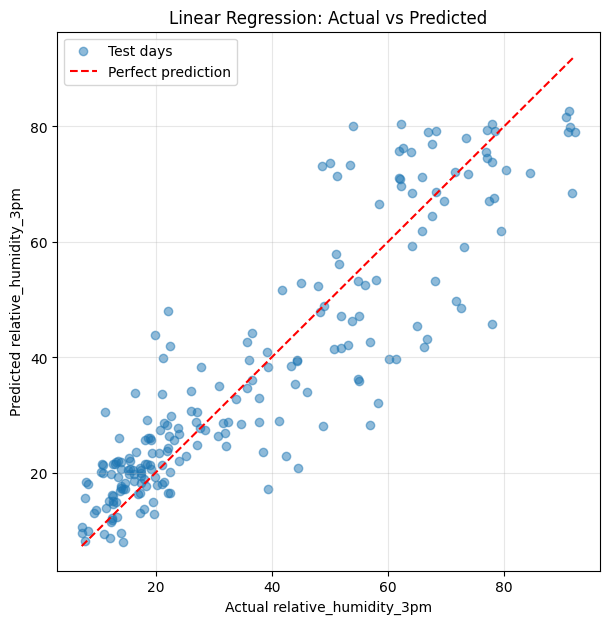

In [13]:
#  — Plot actual vs predicted values
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_lin, alpha=0.5, label="Test days")

low, high = y_test.min(), y_test.max()
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.title("Linear Regression: Actual vs Predicted")
plt.xlabel(f"Actual {TARGET}")
plt.ylabel(f"Predicted {TARGET}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [14]:
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Baseline (average)", "Linear Regression", "Random Forest"],
    "MAE": [
        baseline_mae,
        mean_absolute_error(y_test, y_pred_lin),
        mean_absolute_error(y_test, y_pred_rf),
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred_lin)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf)),
    ],
    "R²": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, y_pred_lin),
        r2_score(y_test, y_pred_rf),
    ],
}).round(3)

comparison

,Model,MAE,RMSE,R²
0,Baseline (average),20.490,23.690,-0.006
1,Linear Regression,7.721,10.349,0.808
2,Random Forest,6.095,8.720,0.864


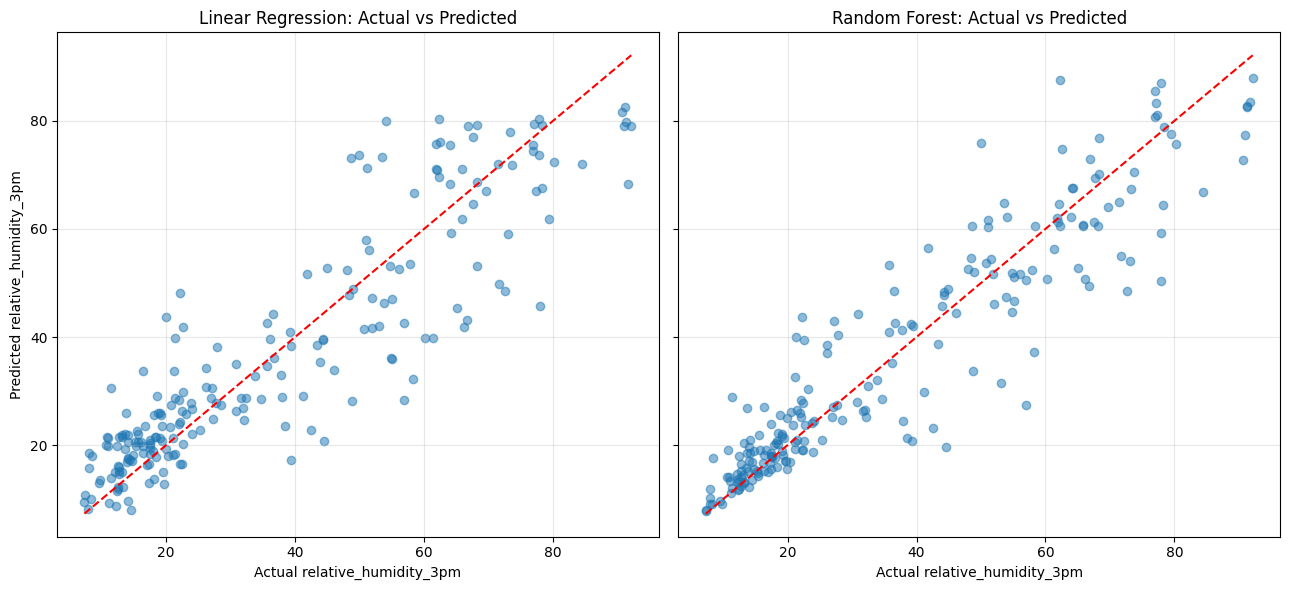

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)

for ax, pred, name in zip(axes, [y_pred_lin, y_pred_rf], ["Linear Regression", "Random Forest"]):
    ax.scatter(y_test, pred, alpha=0.5)
    ax.plot([low, high], [low, high], "r--")
    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel(f"Actual {TARGET}")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel(f"Predicted {TARGET}")
plt.tight_layout()
plt.show()

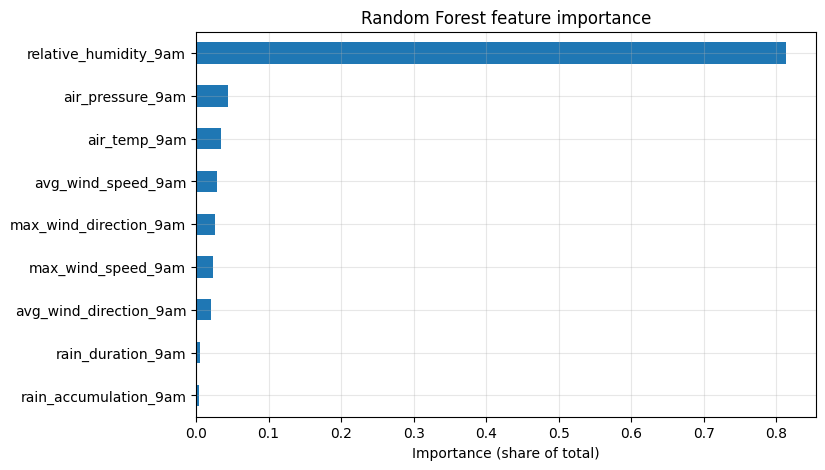

relative_humidity_9am     0.814
air_pressure_9am          0.044
air_temp_9am              0.034
avg_wind_speed_9am        0.029
max_wind_direction_9am    0.026
max_wind_speed_9am        0.023
avg_wind_direction_9am    0.021
rain_duration_9am         0.006
rain_accumulation_9am     0.004
dtype: float64

In [16]:
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh")
plt.title("Random Forest feature importance")
plt.xlabel("Importance (share of total)")
plt.grid(True, alpha=0.3)
plt.show()

importance.sort_values(ascending=False).round(3)

In [17]:
# Predict for a new day
new_day = pd.DataFrame({
    "air_pressure_9am":       [919.0],
    "air_temp_9am":           [60.0],
    "avg_wind_direction_9am": [150.0],
    "avg_wind_speed_9am":     [5.0],
    "max_wind_direction_9am": [160.0],
    "max_wind_speed_9am":     [6.5],
    "rain_accumulation_9am":  [0.0],
    "rain_duration_9am":      [0.0],
    "relative_humidity_9am":  [45.0],
})
new_day = new_day[X.columns]   # make sure the column order matches training

print(f"Linear Regression estimate: {lin_model.predict(new_day)[0]:.1f}")
print(f"Random Forest estimate:     {rf_model.predict(new_day)[0]:.1f}")

Linear Regression estimate: 43.2
Random Forest estimate:     43.9
